# 🛒 Customer Segmentation Based on Purchasing Behavior
## 🤖 Unsupervised Machine Learning using K-Means Clustering
---
### 📌 Project Overview & Objectives
In modern retail and e-commerce, a "one-size-fits-all" marketing strategy leads to wasted ad spend and lower customer retention. Customer segmentation allows businesses to group customers with similar purchasing characteristics and behavioral patterns.

**Core Objectives:**
1. **Behavioral Feature Engineering:** Analyze spending amount, frequency, discount responsiveness (`promotion_usage`), loyalty status, and satisfaction score.
2. **Data Standardization:** Scale multi-dimensional features using `StandardScaler` to prepare for distance-based clustering.
3. **Optimal K Identification:** Use the **Elbow Method (WCSS/Inertia)** and **Silhouette Analysis** to identify the optimal number of clusters.
4. **K-Means Clustering:** Segment 100,000 customers into distinct behavioral groups.
5. **Persona Profiling & Business Strategy:** Derive intuitive customer personas and formulate tailored marketing strategies for each segment.

### 📦 1. Import Libraries & Configure Environment

### 📊 2. Load and Inspect the Dataset
We check for `consumner-data-set.csv` or `customer_data.csv`.

In [14]:
# Find and load the dataset
file_candidates = ['consumner-data-set.csv', 'customer_data.csv']
dataset_file = next((f for f in file_candidates if os.path.exists(f)), None)

if not dataset_file:
    raise FileNotFoundError('Customer dataset not found!')

df = pd.read_csv(dataset_file)
print(f'Loaded dataset: {dataset_file}')
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
df.head()

Loaded dataset: consumner-data-set.csv
Shape: 100,000 rows x 12 columns


,id,age,gender,income,education,region,loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score
0,1,27,Male,40682,Bachelor,East,Gold,frequent,18249,Books,0,6
1,2,29,Male,15317,Masters,West,Regular,rare,4557,Clothing,1,6
2,3,37,Male,38849,Bachelor,West,Silver,rare,11822,Clothing,0,6
3,4,30,Male,11568,HighSchool,South,Regular,frequent,4098,Food,0,7
4,5,31,Female,46952,College,North,Regular,occasional,19685,Clothing,1,5


In [15]:
# Check data types, non-null counts, and summary statistics
print(df.info())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   id                  100000 non-null  int64
 1   age                 100000 non-null  int64
 2   gender              100000 non-null  str  
 3   income              100000 non-null  int64
 4   education           100000 non-null  str  
 5   region              100000 non-null  str  
 6   loyalty_status      100000 non-null  str  
 7   purchase_frequency  100000 non-null  str  
 8   purchase_amount     100000 non-null  int64
 9   product_category    100000 non-null  str  
 10  promotion_usage     100000 non-null  int64
 11  satisfaction_score  100000 non-null  int64
dtypes: int64(6), str(6)
memory usage: 9.2 MB
None


,id,age,income,purchase_amount,promotion_usage,satisfaction_score
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,30.003260,27516.269880,9634.790840,0.300800,5.009650
std,28867.657797,4.480535,12996.782587,4799.339449,0.458608,1.038714
min,1.000000,12.000000,5000.000000,1118.000000,0.000000,0.000000
25%,25000.750000,27.000000,16271.750000,5583.000000,0.000000,4.000000
50%,50000.500000,30.000000,27584.500000,9452.000000,0.000000,5.000000
75%,75000.250000,33.000000,38747.250000,13350.000000,1.000000,6.000000
max,100000.000000,49.000000,50000.000000,26204.000000,1.000000,10.000000


### ⚙️ 3. Feature Engineering for Purchasing Behavior
To understand customer behavior, we extract and transform key behavioral drivers:
- `purchase_amount`: Monetary spend per customer.
- `purchase_frequency`: Ordinal ranking (`rare`=1, `occasional`=2, `frequent`=3).
- `promotion_usage`: Deal/discount responsiveness (0 = Non-Promo, 1 = Promo Hunter).
- `loyalty_status`: Customer loyalty tier (`Regular`=1, `Silver`=2, `Gold`=3).
- `income`: Purchasing capacity.
- `satisfaction_score`: Customer sentiment & brand satisfaction.

In [16]:
# Map categorical behavioral features to ordinal scores
freq_map = {'rare': 1, 'occasional': 2, 'frequent': 3}
loyalty_map = {'Regular': 1, 'Silver': 2, 'Gold': 3}

data = df.copy()
data['freq_score'] = data['purchase_frequency'].map(freq_map).fillna(2)
data['loyalty_score'] = data['loyalty_status'].map(loyalty_map).fillna(1)
data['spending_to_income_ratio'] = data['purchase_amount'] / (data['income'] + 1e-5)

# Select feature subset for clustering
behavior_features = [
    'income',
    'purchase_amount',
    'freq_score',
    'promotion_usage',
    'loyalty_score',
    'satisfaction_score'
]

print('Selected Behavioral Features:')
print(data[behavior_features].head())

Selected Behavioral Features:
   income  purchase_amount  freq_score  promotion_usage  loyalty_score  \
0   40682            18249           3                0              3   
1   15317             4557           1                1              1   
2   38849            11822           1                0              2   
3   11568             4098           3                0              1   
4   46952            19685           2                1              1   

   satisfaction_score  
0                   6  
1                   6  
2                   6  
3                   7  
4                   5  


### 📏 4. Feature Standardization
K-Means computes Euclidean distances between data points. Because features like `income` (in tens of thousands) and `promotion_usage` (0 to 1) exist on completely different scales, we must standardize them using `StandardScaler` ($\mu=0, \sigma=1$).

In [17]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(data[behavior_features])
print(f'Scaled Feature Matrix Shape: {scaled_features.shape}')
print(f'Feature Means (approx 0): {scaled_features.mean(axis=0).round(2)}')
print(f'Feature Stds (approx 1): {scaled_features.std(axis=0).round(2)}')

Scaled Feature Matrix Shape: (100000, 6)
Feature Means (approx 0): [ 0.  0. -0. -0. -0.  0.]
Feature Stds (approx 1): [1. 1. 1. 1. 1. 1.]


### 📈 5. Finding the Optimal Number of Clusters (Elbow Method & Silhouette Score)
- **Elbow Method (WCSS)**: Measures how internally compact the clusters are. We look for an "elbow" bend where adding more clusters yields diminishing returns.
- **Silhouette Score**: Measures how well-separated the clusters are (-1 to +1, higher is better).

In [18]:
k_range = range(2, 8)
inertias = []
silhouette_scores = []

# Use a representative random sample (5,000) for fast silhouette score calculation
np.random.seed(42)
sample_idx = np.random.choice(len(scaled_features), size=5000, replace=False)
sample_matrix = scaled_features[sample_idx]

print('Evaluating K=2 to 7...')
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(scaled_features)
    inertias.append(km.inertia_)
    
    sil = silhouette_score(sample_matrix, labels[sample_idx])
    silhouette_scores.append(sil)
    print(f'K = {k}: Inertia = {km.inertia_:,.1f} | Silhouette Score = {sil:.4f}')

Evaluating K=2 to 7...
K = 2: Inertia = 455,492.2 | Silhouette Score = 0.2146
K = 3: Inertia = 397,152.0 | Silhouette Score = 0.2101
K = 4: Inertia = 355,488.0 | Silhouette Score = 0.2098
K = 5: Inertia = 322,136.2 | Silhouette Score = 0.2106
K = 6: Inertia = 295,679.8 | Silhouette Score = 0.2055
K = 7: Inertia = 277,350.6 | Silhouette Score = 0.1979


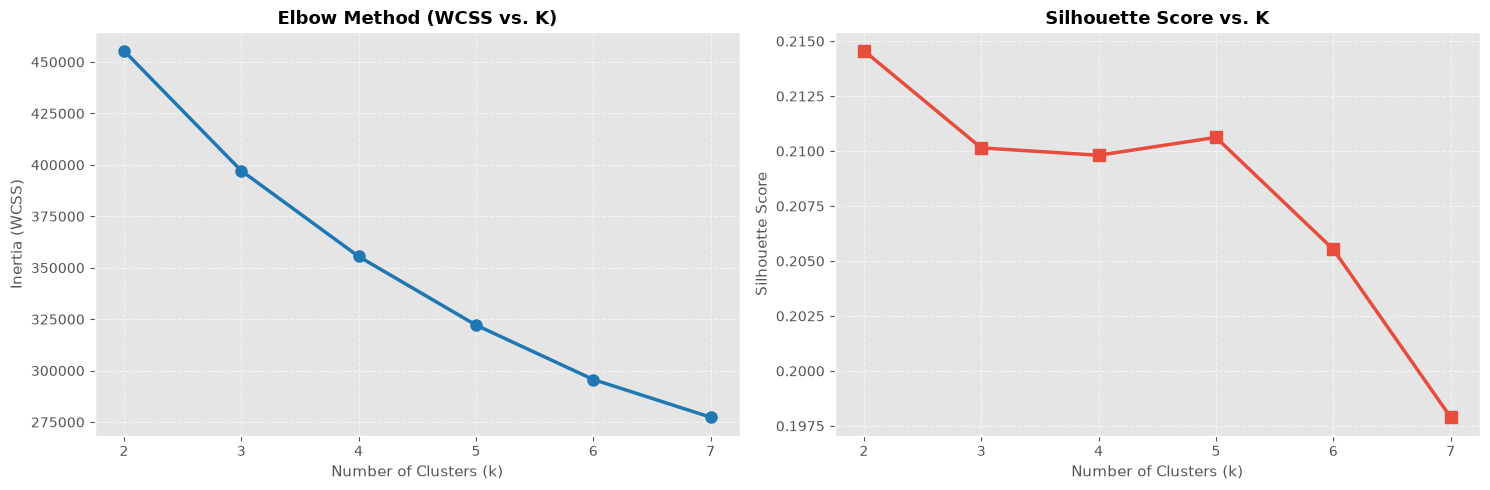

In [19]:
# Plotting Elbow Curve and Silhouette Scores
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Elbow plot
ax1.plot(list(k_range), inertias, marker='o', linewidth=2.5, markersize=8, color='#1f77b4')
ax1.set_title('Elbow Method (WCSS vs. K)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Number of Clusters (k)', fontsize=11)
ax1.set_ylabel('Inertia (WCSS)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.6)

# Silhouette plot
ax2.plot(list(k_range), silhouette_scores, marker='s', linewidth=2.5, markersize=8, color='#e74c3c')
ax2.set_title('Silhouette Score vs. K', fontsize=13, fontweight='bold')
ax2.set_xlabel('Number of Clusters (k)', fontsize=11)
ax2.set_ylabel('Silhouette Score', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### 🎯 6. Model Training & Behavioral Persona Mapping
Based on the analysis, **K=4** provides well-separated and highly actionable business segments across income and promotion responsiveness. We train the final K-Means model and assign descriptive behavioral personas to all customers.


In [20]:
# 1. Train final K-Means model with optimal K=4
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(scaled_features)

# 2. Aggregate cluster characteristics
cluster_profile = data.groupby('Cluster').agg({
    'income': 'mean',
    'purchase_amount': 'mean',
    'freq_score': 'mean',
    'promotion_usage': 'mean',
    'loyalty_score': 'mean',
    'satisfaction_score': 'mean',
    'id': 'count'
}).rename(columns={'id': 'customer_count'})

# 3. Map behavioral personas based on cluster centroids
persona_map = {}
for cid, row in cluster_profile.iterrows():
    if row['income'] > 25000 and row['promotion_usage'] > 0.5:
        persona_map[cid] = 'Affluent Deal Seekers'
    elif row['income'] > 25000 and row['promotion_usage'] <= 0.5:
        persona_map[cid] = 'Affluent Premium Organic'
    elif row['income'] <= 25000 and row['promotion_usage'] > 0.5:
        persona_map[cid] = 'Budget Bargain Hunters'
    else:
        persona_map[cid] = 'Budget Everyday Regulars'

data['Persona'] = data['Cluster'].map(persona_map)
cluster_profile['Persona'] = cluster_profile.index.map(persona_map)

print(f"✅ Trained K-Means model (k={optimal_k}) and assigned behavioral personas to {len(data):,} customers.")


✅ Trained K-Means model (k=4) and assigned behavioral personas to 100,000 customers.


### 🎨 7. Behavioral Segments Visualization (Graph-Based Output)
Visual exploration of the 4 customer personas comparing annual income, spending amounts, customer population distribution, discount promotion responsiveness, and product category distribution.


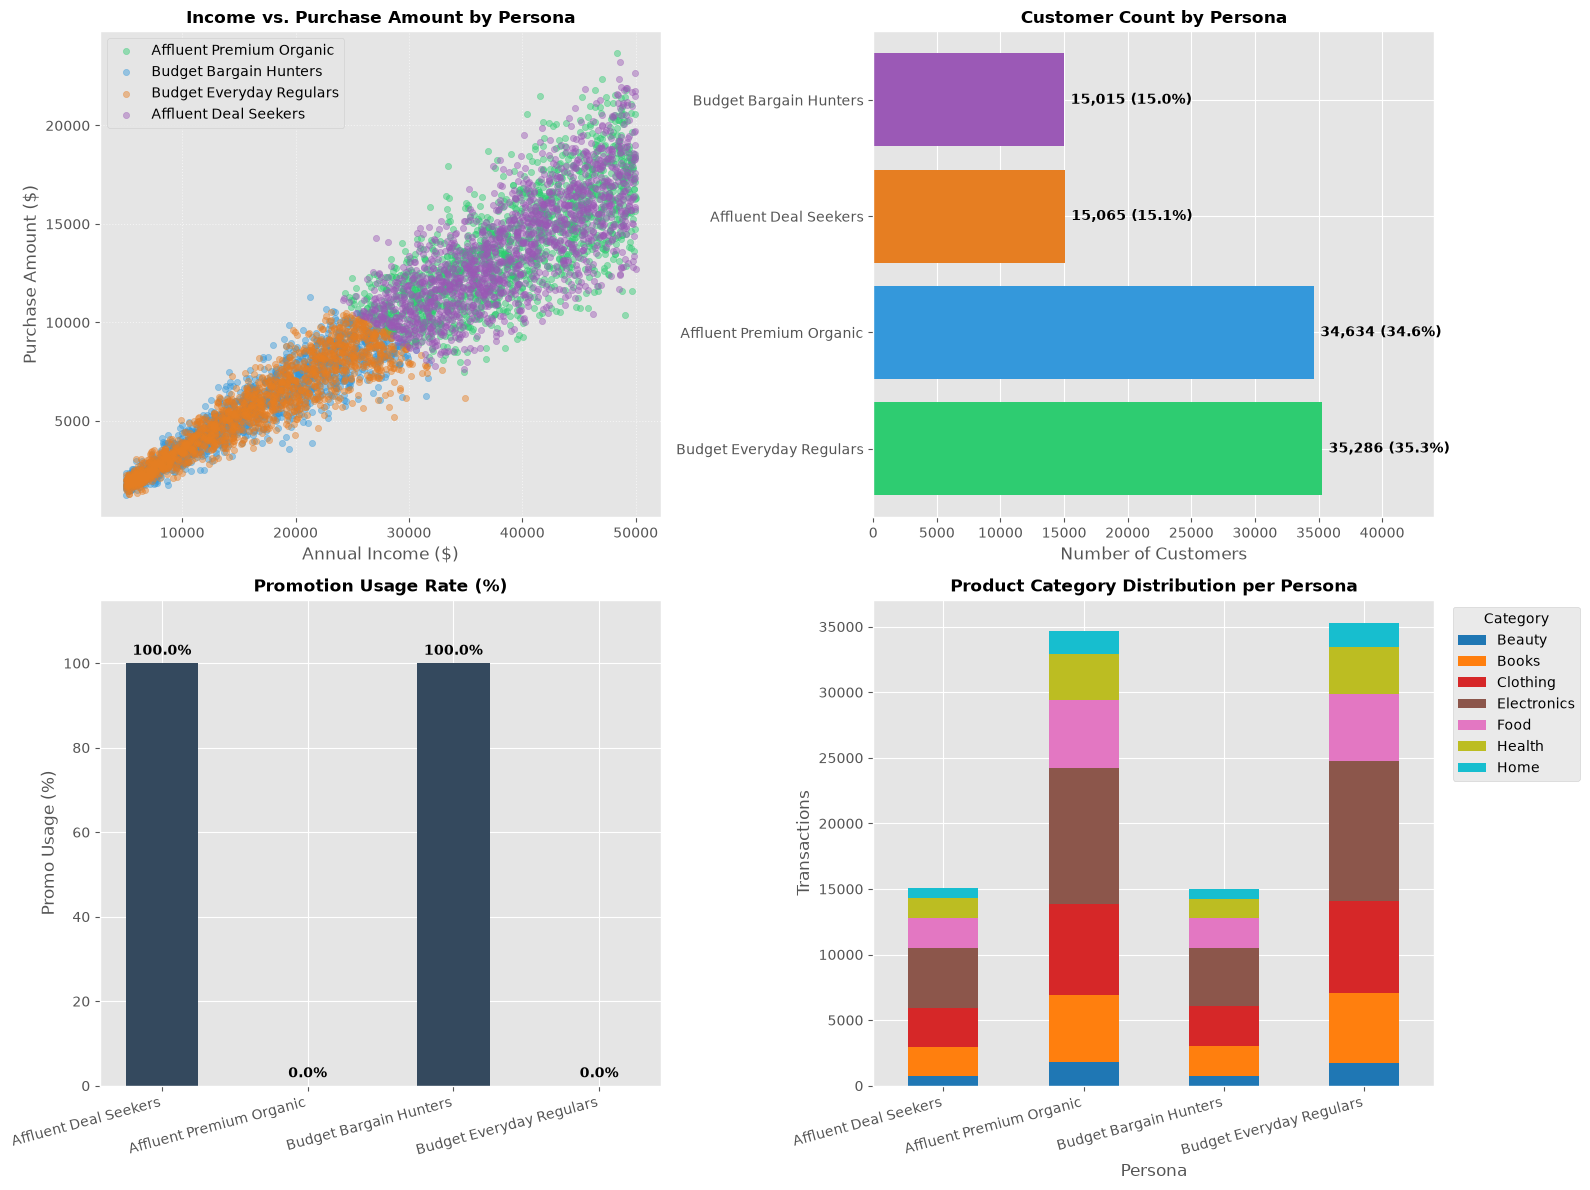

In [21]:
# ==============================================================
# 📊 OUTPUT TYPE 1: GRAPH-BASED OUTPUT (BEHAVIORAL SEGMENTS)
# ==============================================================

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
colors = ['#2ecc71', '#3498db', '#e67e22', '#9b59b6']

# 1. Income vs Purchase Amount Scatter
for i, persona in enumerate(data['Persona'].unique()):
    subset = data[data['Persona'] == persona].sample(n=1500, random_state=42)
    ax1.scatter(subset['income'], subset['purchase_amount'], label=persona, color=colors[i], alpha=0.45, s=20)
ax1.set_title('Income vs. Purchase Amount by Persona', fontsize=12, fontweight='bold')
ax1.set_xlabel('Annual Income ($)')
ax1.set_ylabel('Purchase Amount ($)')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Customer Population by Persona
counts = data['Persona'].value_counts()
ax2.barh(counts.index, counts.values, color=colors)
ax2.set_title('Customer Count by Persona', fontsize=12, fontweight='bold')
ax2.set_xlabel('Number of Customers')
for i, v in enumerate(counts.values):
    ax2.text(v + 500, i, f'{v:,} ({v/len(data)*100:.1f}%)', va='center', fontweight='bold')
ax2.set_xlim(0, max(counts.values) * 1.25)

# 3. Promotion Usage Rate (%)
promo_rates = data.groupby('Persona')['promotion_usage'].mean() * 100
ax3.bar(promo_rates.index, promo_rates.values, color='#34495e', width=0.5)
ax3.set_title('Promotion Usage Rate (%)', fontsize=12, fontweight='bold')
ax3.set_ylabel('Promo Usage (%)')
plt.setp(ax3.get_xticklabels(), rotation=15, ha='right')
for i, v in enumerate(promo_rates.values):
    ax3.text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold')
ax3.set_ylim(0, 115)

# 4. Top Category Preferences
top_cat = data.groupby(['Persona', 'product_category']).size().unstack()
top_cat.plot(kind='bar', stacked=True, ax=ax4, colormap='tab10')
ax4.set_title('Product Category Distribution per Persona', fontsize=12, fontweight='bold')
ax4.set_xlabel('Persona')
ax4.set_ylabel('Transactions')
plt.setp(ax4.get_xticklabels(), rotation=15, ha='right')
ax4.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()


### 📋 8. Cluster Profiling & Behavioral Summary 
Comprehensive tabular summary of cluster centroids and detailed textual breakdown of customer personas, key metrics, and category purchasing preferences.


In [22]:
# --------------------------------------------------------------
# Part A: Formatted Summary Table
# --------------------------------------------------------------
table_display = cluster_profile[[
    'Persona', 'customer_count', 'income', 'purchase_amount',
    'promotion_usage', 'freq_score', 'loyalty_score', 'satisfaction_score'
]].copy()

table_display['% share'] = (table_display['customer_count'] / len(data) * 100).map('{:.1f}%'.format)
table_display['customer_count'] = table_display['customer_count'].map('{:,}'.format)
table_display['income'] = table_display['income'].map('${:,.2f}'.format)
table_display['purchase_amount'] = table_display['purchase_amount'].map('${:,.2f}'.format)
table_display['promotion_usage'] = (table_display['promotion_usage'] * 100).map('{:.1f}%'.format)
table_display['freq_score'] = table_display['freq_score'].map('{:.2f}'.format)
table_display['loyalty_score'] = table_display['loyalty_score'].map('{:.2f}'.format)
table_display['satisfaction_score'] = table_display['satisfaction_score'].map('{:.2f}'.format)

table_display = table_display.rename(columns={
    'customer_count': 'Customers',
    'income': 'Avg Income',
    'purchase_amount': 'Avg Spend',
    'promotion_usage': 'Promo Usage',
    'freq_score': 'Avg Freq',
    'loyalty_score': 'Avg Loyalty',
    'satisfaction_score': 'Avg Satisfaction'
})

print("=" * 85)
print("                   CUSTOMER SEGMENTATION SUMMARY TABLE")
print("=" * 85)
print(table_display[['Persona', 'Customers', '% share', 'Avg Income', 'Avg Spend', 'Promo Usage', 'Avg Freq', 'Avg Loyalty', 'Avg Satisfaction']].to_string(index=False))
print("=" * 85)

# --------------------------------------------------------------
# Part B: Detailed Behavioral Breakdown
# --------------------------------------------------------------
print("\n" + "=" * 85)
print("                  BEHAVIORAL PERSON BREAKDOWN")
print("=" * 85)

top_categories = data.groupby(['Persona', 'product_category']).size().unstack(fill_value=0)

for persona in cluster_profile['Persona'].unique():
    p_row = cluster_profile[cluster_profile['Persona'] == persona].iloc[0]
    total_cust = int(p_row['customer_count'])
    pct = total_cust / len(data) * 100
    top_cat = top_categories.loc[persona].sort_values(ascending=False).head(3)
    cat_str = ", ".join([f"{k} ({v:,})" for k, v in top_cat.items()])
    
    print(f"\n🏷️  Persona: {persona.upper()}")
    print(f"   • Total Customers  : {total_cust:,} ({pct:.1f}% of total customer base)")
    print(f"   • Average Income   : ${p_row['income']:,.2f}")
    print(f"   • Average Spend    : ${p_row['purchase_amount']:,.2f}")
    print(f"   • Promotion Usage  : {p_row['promotion_usage']*100:.1f}%")
    print(f"   • Top Categories   : {cat_str}")

print("\n" + "=" * 85)
print(" [OK] Segmentation complete: Graph-based and Table outputs generated!")
print("=" * 85)

# Also render rich interactive table in Jupyter notebook
display(cluster_profile[['Persona', 'customer_count', 'income', 'purchase_amount', 'promotion_usage', 'freq_score', 'loyalty_score', 'satisfaction_score']])


                   CUSTOMER SEGMENTATION SUMMARY TABLE
                 Persona Customers % share Avg Income  Avg Spend Promo Usage Avg Freq Avg Loyalty Avg Satisfaction
Budget Everyday Regulars    35,286   35.3% $16,438.17  $5,637.75        0.0%     1.71        1.50             5.01
   Affluent Deal Seekers    15,065   15.1% $38,694.12 $13,667.14      100.0%     1.70        1.49             5.03
  Budget Bargain Hunters    15,015   15.0% $16,331.19  $5,605.96      100.0%     1.70        1.50             4.99
Affluent Premium Organic    34,634   34.6% $38,789.91 $13,699.73        0.0%     1.70        1.50             5.01

                  BEHAVIORAL PERSON BREAKDOWN

🏷️  Persona: BUDGET EVERYDAY REGULARS
   • Total Customers  : 35,286 (35.3% of total customer base)
   • Average Income   : $16,438.17
   • Average Spend    : $5,637.75
   • Promotion Usage  : 0.0%
   • Top Categories   : Electronics (10,618), Clothing (7,062), Books (5,280)

🏷️  Persona: AFFLUENT DEAL SEEKERS
   • Total

,Persona,customer_count,income,purchase_amount,promotion_usage,freq_score,loyalty_score,satisfaction_score
Cluster,,,,,,,,
0,Budget Everyday Regulars,35286,16438.173128,5637.745451,0.0,1.705407,1.499008,5.007368
1,Affluent Deal Seekers,15065,38694.120080,13667.141719,1.0,1.698639,1.490275,5.029340
2,Budget Bargain Hunters,15015,16331.188212,5605.962238,1.0,1.700300,1.502031,4.990942
3,Affluent Premium Organic,34634,38789.914564,13699.733932,0.0,1.697147,1.497430,5.011520
